# 08 · Real-world check

**Question:** given a district's real soil and weather, does the system recommend the crops that district actually grows?

- **Soil:** Soil Health Card (SHC) tests 2023-25, India Data Portal. The file only counts samples per class
  (N, P, K Low/Medium/High; pH Acidic/Neutral/Alkaline), so `data.district_soil()` takes the count-weighted mean of class
  values (ICAR limits N 280/560, P 10/25, K 120/280 kg/ha, pH 6.5/7.5; class midpoints).
- **Weather:** NASA POWER 2015-2024 at the district's market coordinates, the same as the app.
- **What districts grow:** DES area, Kaggle crops only, crops reported 2018-19 or later (mean of the last 5 years).
  *Main crop* = the one with the most area.
- **System:** `recommend.recommend()` as the app calls it, sown Nov 3 (only affects price, so only the near-tie order).

**Scale problem.** Kaggle's N, P, K are not soil test values: Kaggle N is 0–140 (median 37), while SHC calls
anything under 280 kg/ha "Low". Kaggle's per-crop means look like fertiliser doses (rice 80:48:40). So three soil inputs:
1. **SHC raw**: the kg/ha a farmer would copy from their card. This is what the app will get.
2. **SHC mapped**: each district's SHC value → its percentile among districts → the same percentile of Kaggle's values.
   Keeps which districts are richer, drops the units. Best case for the model. pH is on the same scale and stays raw.
3. **Kaggle mean soil**: every district gets the same soil, so only weather differs. Tells us whether soil adds anything.

**Metrics** per district: main crop ranked 1st; main crop anywhere in the list; share of recommended crops the district
grows at all. **Baselines:** 3 random crops; the 3 crops that are most often a main crop (a popularity rule, which sees
the answers, so it is an upper-bound-ish baseline).

In [1]:
import sys
sys.path.insert(0, '../project')
import datetime
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import data
import recommend

SEED = 42
SOW = datetime.date(2026, 11, 3)
RESULTS, FIGS = Path('../research/results'), Path('../research/figures')
pd.set_option('display.width', 220)

## 1. Data

In [2]:
soil = data.district_soil().dropna()
soil = soil[soil.samples >= 100]  # a few districts have only a handful of tests
grown = data.district_yield()
grown = grown[grown.last_year >= '2018-2019']
districts = recommend._tables()[2]  # districts with coordinates (the ones the app can serve)
d = districts.merge(soil, on='district_code')
d = d[d.district_code.isin(grown.district_code)].reset_index(drop=True)
main = grown.loc[grown.groupby('district_code').area_ha.idxmax()].set_index('district_code').crop
grown_sets = grown.groupby('district_code').crop.apply(set)
print(f'{len(soil)} districts with SHC soil, {len(districts)} with coordinates, {len(d)} with soil + coordinates + DES area')
print(f"SHC tests per district: median {d.samples.median():,.0f}, min {d.samples.min():,.0f}")

647 districts with SHC soil, 625 with coordinates, 539 with soil + coordinates + DES area
SHC tests per district: median 16,239, min 102


In [3]:
kaggle = data.kaggle_crops()
q = [0.05, 0.25, 0.5, 0.75, 0.95]
pd.concat({'SHC districts': d[['N', 'P', 'K', 'ph']].quantile(q), 'Kaggle rows': kaggle[['N', 'P', 'K', 'ph']].quantile(q)}, axis=1).round(1)

SHC districts                   Kaggle rows                   
                 N     P      K   ph           N      P      K   ph
0.05         210.2  12.1  161.7  6.2         4.0   10.0   15.0  5.4
0.25         213.4  17.2  198.1  6.9        21.0   28.0   20.0  6.0
0.50         244.8  21.5  234.0  7.0        37.0   51.0   32.0  6.4
0.75         321.4  27.4  286.5  7.0        84.2   68.0   49.0  6.9
0.95         479.4  31.6  337.3  7.1       116.0  133.0  199.0  7.7

Every district's SHC nitrogen is above Kaggle's maximum (140), and the median district's K (234) is above Kaggle's maximum (205).
P is the other way round: SHC P (kg P/ha) is mostly below Kaggle's median. Fed raw, the model sees soils it never trained on.

In [4]:
def to_kaggle_scale(col):
    pct = d[col].rank(pct=True) - 0.5 / len(d)  # mid-rank percentile, stays inside (0, 1)
    return np.quantile(kaggle[col], pct)


mapped = d.assign(**{c: to_kaggle_scale(c) for c in ['N', 'P', 'K']})
mean_soil = d.assign(**kaggle[['N', 'P', 'K', 'ph']].mean().to_dict())
variants = {'SHC raw': d, 'SHC mapped': mapped, 'Kaggle mean soil': mean_soil}

## 2. Run the system on every district

In [5]:
rows = []
for name, v in variants.items():
    for r in v.itertuples():
        _, t = recommend.recommend(r.N, r.P, r.K, r.ph, r.district_name, r.state_name, sow=SOW)
        rows.append({'variant': name, 'district_code': r.district_code, 'state': r.state_name, 'district': r.district_name,
                     'N': r.N, 'P': r.P, 'K': r.K, 'ph': r.ph, 'picks': list(t.crop), 'top_suitability': t.suitability.iloc[0]})
picks = pd.DataFrame(rows)
picks['main_crop'] = picks.district_code.map(main)
picks['crops_grown'] = picks.district_code.map(grown_sets)
picks.groupby('variant').size()

variant
Kaggle mean soil    539
SHC mapped          539
SHC raw             539
dtype: int64

## 3. Match rates

In [6]:
def score(p):
    return pd.Series({
        'districts': len(p),
        'main crop 1st %': (p.picks.str[0] == p.main_crop).mean() * 100,
        'main crop in list %': np.mean([m in k for m, k in zip(p.main_crop, p.picks)]) * 100,
        'picks grown %': np.mean([np.mean([c in g for c in k]) for k, g in zip(p.picks, p.crops_grown)]) * 100,
        'list length': p.picks.str.len().mean(),
    })


rng = np.random.default_rng(SEED)
classes = sorted(kaggle.label.unique())
base = picks[picks.variant == 'SHC raw'][['main_crop', 'crops_grown']]
popular = list(main.loc[d.district_code].value_counts().index[:3])
baselines = {
    'random 3 crops': base.assign(picks=[list(rng.choice(classes, 3, replace=False)) for _ in range(len(base))]),
    f'popularity ({", ".join(popular)})': base.assign(picks=[popular] * len(base)),
}
summary = pd.DataFrame({**{k: score(g) for k, g in picks.groupby('variant', sort=False)},
                        **{k: score(b) for k, b in baselines.items()}}).T
summary.round(1)

,districts,main crop 1st %,main crop in list %,picks grown %,list length
SHC raw,539.0,6.3,7.8,29.7,3.0
SHC mapped,539.0,3.5,13.2,37.4,2.0
Kaggle mean soil,539.0,0.0,1.7,1.6,1.0
random 3 crops,539.0,5.0,16.0,35.1,3.0
"popularity (rice, cotton, maize)",539.0,69.6,87.6,83.9,3.0


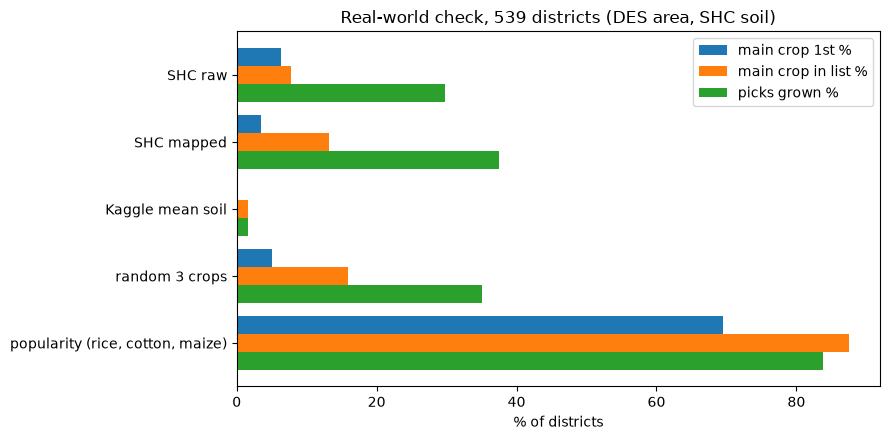

In [7]:
summary.round(2).rename_axis('method').to_csv(RESULTS / '2026-11-03_real_world_check.csv')
picks.assign(picks=picks.picks.str.join(' > '), crops_grown=picks.crops_grown.map(sorted).str.join(' ')).to_csv(
    RESULTS / '2026-11-03_real_world_picks.csv', index=False)

ax = summary[['main crop 1st %', 'main crop in list %', 'picks grown %']].plot.barh(figsize=(9, 4.5), width=0.8)
ax.invert_yaxis(); ax.set_xlabel('% of districts'); ax.set_title(f'Real-world check, {len(d)} districts (DES area, SHC soil)')
plt.tight_layout(); plt.savefig(FIGS / 'real_world_check.png', dpi=150)

## 4. What the model picks vs what districts grow

In [8]:
first = pd.DataFrame({v: picks[picks.variant == v].picks.str[0].value_counts(normalize=True) * 100 for v in variants})
first['main crop (DES)'] = main.loc[d.district_code].value_counts(normalize=True) * 100
first.fillna(0).round(1).sort_values('main crop (DES)', ascending=False)

,SHC raw,SHC mapped,Kaggle mean soil,main crop (DES)
picks,,,,
rice,0.0,0.7,0.0,69.6
cotton,0.0,6.1,0.0,9.3
maize,0.0,7.1,0.0,8.7
chickpea,88.5,10.9,0.0,6.3
coconut,0.0,1.3,0.0,2.8
blackgram,0.0,5.0,0.0,1.9
pigeonpeas,0.0,0.9,0.0,0.7
mungbean,0.0,6.1,0.0,0.4
banana,0.0,1.3,0.0,0.2


In [9]:
# Main crop missed: which crops does the best variant miss, and what does it pick instead?
best = max(variants, key=lambda v: summary.loc[v, 'main crop in list %'])
p = picks[picks.variant == best]
miss = p[[m not in k for m, k in zip(p.main_crop, p.picks)]]
print(best, '- main crop not in list:', len(miss), 'of', len(p))
pd.crosstab(miss.main_crop, miss.picks.str[0]).loc[lambda t: t.sum(1).sort_values(ascending=False).index].head(8)

SHC mapped - main crop not in list: 468 of 539


picks,apple,banana,blackgram,chickpea,coconut,coffee,cotton,grapes,jute,kidneybeans,lentil,maize,mango,mothbeans,mungbean,orange,papaya,pigeonpeas,pomegranate,watermelon
main_crop,,,,,,,,,,,,,,,,,,,,
rice,0,2,18,26,7,22,27,16,2,0,10,31,31,2,27,40,36,5,19,1
cotton,2,1,4,14,0,2,0,3,2,0,1,1,0,0,1,0,10,0,8,1
maize,0,0,1,2,0,6,5,3,3,0,3,0,3,0,2,1,10,0,4,0
chickpea,0,0,2,0,0,2,0,1,1,0,0,0,2,0,3,0,5,0,5,1
coconut,0,0,2,2,0,1,1,0,0,1,2,0,0,0,0,3,2,0,1,0
blackgram,0,0,0,1,0,2,0,1,0,0,0,1,0,0,0,0,2,0,1,0
pigeonpeas,0,0,0,1,0,0,0,1,0,0,0,0,0,0,0,0,2,0,0,0
mungbean,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,1,0,0,0


In [10]:
# Rice is the main crop in many districts. Weather at those districts vs Kaggle rice rows.
wx = pd.DataFrame([recommend.weather(r.lat, r.lon) for r in d.itertuples()], index=d.district_code)
rice_d = main[main == 'rice'].index.intersection(d.district_code)
pd.DataFrame({'rice districts (NASA)': wx.loc[rice_d, ['temperature', 'rainfall']].median(),
              'Kaggle rice rows': kaggle[kaggle.label == 'rice'][['temperature', 'rainfall']].median()}).round(1)

,rice districts (NASA),Kaggle rice rows
temperature,25.8,23.7
rainfall,106.0,233.1


## 5. Why: weather or soil?

Two diagnostics with the crop model alone (top 3 by suitability, no money):
- **Season weather.** Kaggle's rainfall may be growing-season rain, not the annual monthly mean the app uses.
  Try Jun–Sep (kharif) and Nov–Feb (rabi) means instead.
- **Oracle soil.** Give each district the Kaggle mean soil of *its own main crop* (this leaks the answer). If the model
  still misses, the weather is the problem; if it now hits, the soil is.

In [11]:
m = recommend._model()
cls = np.array(m['classes'])
mc = main.loc[d.district_code].values
oracle_soil = kaggle.groupby('label')[['N', 'P', 'K', 'ph']].mean().loc[mc].reset_index(drop=True)


def season(months):
    w = [data.nasa_weather(round(r.lat, 2), round(r.lon, 2)) for r in d.itertuples()]
    return pd.DataFrame([x[x.index.month.isin(months)].mean() for x in w])[['temperature', 'rainfall']]


def top3(soil_df, w):
    X = pd.concat([soil_df[['N', 'P', 'K', 'ph']].reset_index(drop=True), w], axis=1)[m['features']]
    picks = cls[np.argsort(-m['model'].predict_proba(X), axis=1)[:, :3]]
    return pd.Series({'main crop 1st %': np.mean(picks[:, 0] == mc) * 100,
                      'main crop in top 3 %': np.mean([a in b for a, b in zip(mc, picks)]) * 100,
                      'rice 1st in rice districts %': np.mean(picks[mc == 'rice', 0] == 'rice') * 100,
                      'median rainfall mm/month': w.rainfall.median()})


seasons = {'annual': range(1, 13), 'kharif Jun-Sep': [6, 7, 8, 9], 'rabi Nov-Feb': [11, 12, 1, 2]}
wx_s = {k: season(v) for k, v in seasons.items()}
diag = pd.DataFrame({**{f'SHC mapped, {k}': top3(mapped, w) for k, w in wx_s.items()},
                     **{f'oracle soil, {k}': top3(oracle_soil, wx_s[k]) for k in ['annual', 'kharif Jun-Sep']}}).T
diag.round(2).rename_axis('setting').to_csv(RESULTS / '2026-11-03_real_world_diagnostics.csv')
diag.round(1)

,main crop 1st %,main crop in top 3 %,rice 1st in rice districts %,median rainfall mm/month
"SHC mapped, annual",3.5,15.0,1.1,95.8
"SHC mapped, kharif Jun-Sep",4.5,16.5,2.9,224.6
"SHC mapped, rabi Nov-Feb",4.8,14.3,2.7,11.4
"oracle soil, annual",30.4,99.6,2.4,95.8
"oracle soil, kharif Jun-Sep",33.0,100.0,5.9,224.6


## 6. Findings

1. **On real districts the system is no better than chance.** With SHC soil the main crop (by DES area) is in the
   list for 8–13% of 539 districts; 3 random crops manage 16%, and always saying "rice, cotton, maize" manages 88%.
2. **Kaggle N, P, K are not soil test values.** SHC nitrogen is 210–650 kg/ha in every district; Kaggle N tops out at
   140. Fed raw card values, the model says chickpea in 89% of districts. A farmer typing their Soil Health Card into
   the app would get this.
3. **Weather is not the cause.** Season-matched rainfall (kharif median 225 mm vs Kaggle rice 233) leaves the result
   unchanged. With oracle soil the main crop is in the top 3 for ~100% of districts, with either weather.
4. **So the model reads the crop from the soil pattern.** Each Kaggle crop has its own tight N-P-K cluster, which
   looks like that crop's fertiliser recommendation rather than a field's soil. Real soil never lands in those clusters.
   This is the strongest evidence yet that the Kaggle data is synthetic and does not transfer.
5. Caveats: district means blur farm-to-farm variation; SHC only gives class counts, so values are class midpoints;
   main crop is limited to the 22 Kaggle crops (no wheat, sugarcane, soybean, groundnut).